# 11. Simulated brand data

This notebook walks through `simulate_brand_data`, the data-generating process (DGP) behind the practitioner guide, the tests and the docs pages. It returns a `BrandData` with the series and a `BrandTruth` with the parameters that made them.

The earlier notebooks each built a small two- or three-variable DGP by hand. That was enough to check one feature at a time. The brand use case needed one shared system with known answers, so every check could ask the same question: did the model find the truth?

**What this notebook covers:**

1. The system: three cointegrated brand series and five drivers.
2. `BrandTruth`: the parameters, and the checks they satisfy by construction.
3. `exog_lag_share`: part of each driver effect arrives a week late.
4. `exog_unit_root`: a driver that trends, and why it enters as a change.

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np

from bayesian_vecm import BrandData, BrandTruth, simulate_brand_data

np.set_printoptions(precision=4, suppress=True)

## 1. The system

The DGP is a VECM with an unrestricted constant and one lag of differences:

$$
\Delta y_t = c + \alpha \beta^\top y_{t-1} + \Gamma \Delta y_{t-1} + B x_t + \varepsilon_t,
\qquad \varepsilon_t \sim \mathcal{N}(0, \Sigma).
$$

The causal story is a chain:

$$
\text{marketing channels} \rightarrow \text{awareness} \rightarrow \text{consideration} \rightarrow \text{sales}.
$$

- **Endogenous series** (`endog`): log levels of `organic_sales`, `brand_awareness` and `brand_consideration`. Weekly, 260 weeks by default.
- **Drivers** (`exog`): three marketing channels and two macro series. All five are stationary AR(1) processes around zero.
- **One common trend.** Three series and one trend give cointegration rank 2.

The defaults are `n_obs=260` and `seed=14`. The same seed always gives the same data.

In [2]:
data = simulate_brand_data()
assert isinstance(data, BrandData)
assert isinstance(data.truth, BrandTruth)

print("endog:", data.endog.shape, list(data.endog.columns))
print("exog: ", data.exog.shape, list(data.exog.columns))
print()
print(data.endog.head(3).round(4))

endog: (260, 3) ['organic_sales', 'brand_awareness', 'brand_consideration']
exog:  (260, 5) ['brand_spend', 'pr_reach', 'sponsorship_reach', 'interest_rate', 'consumer_confidence']

            organic_sales  brand_awareness  brand_consideration
2021-01-04         6.9078           2.9957               2.3026
2021-01-11         6.9154           2.9785               2.3028
2021-01-18         6.9082           2.9607               2.2958


`endog` holds logs. `np.exp` gives the original units: sales start at 1,000 and the two brand metrics are percentages starting at 20% and 10%.

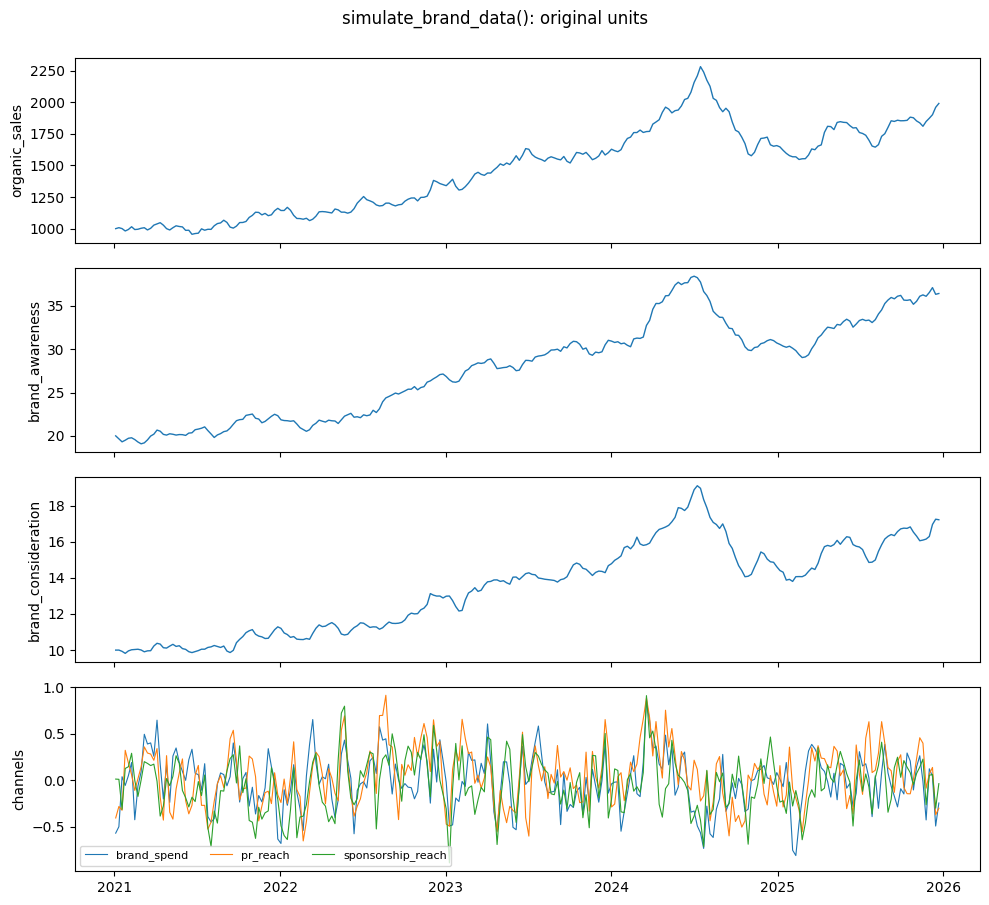

Log growth over the sample:
organic_sales          0.689
brand_awareness        0.600
brand_consideration    0.543
dtype: float64


In [3]:
levels = np.exp(data.endog)

fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for ax, name in zip(axes[:3], levels.columns, strict=True):
    ax.plot(levels.index, levels[name], lw=1)
    ax.set_ylabel(name)
for name in ["brand_spend", "pr_reach", "sponsorship_reach"]:
    axes[3].plot(data.exog.index, data.exog[name], lw=0.8, label=name)
axes[3].set_ylabel("channels")
axes[3].legend(fontsize=8, ncol=3)
fig.suptitle("simulate_brand_data(): original units", y=1.0)
plt.tight_layout()
plt.show()

growth = data.endog.iloc[-1] - data.endog.iloc[0]
print("Log growth over the sample:")
print(growth.round(3))

Sales are built to double over 260 weeks on average. One seed drifts above or below that because the common trend is a random walk.

## 2. `BrandTruth`: the parameters

`data.truth` is a frozen dataclass. Every array has rows in `endog` order and, for `b`, columns in `exog` order. The three checks below hold by construction:

- **`beta` is orthogonal to the trend loading.** `beta.T @ loading` is zero, so both cointegrating relations cancel the common trend.
- **Awareness is weakly exogenous.** Its row of `alpha` is zero. It never adjusts to the long-run relations, so its shocks are the only ones that last.
- **Each driver acts on one series.** The channels move awareness and the macro series move consideration. Sales get no direct driver effect.

In [4]:
truth = data.truth
print("beta (top 2x2 block is the identity):")
print(truth.beta)
print()
print("beta.T @ loading =", truth.beta.T @ truth.loading)
print()
print("alpha (rows: sales, awareness, consideration):")
print(truth.alpha)
print()
print("b (rows: endog, columns: exog):")
print(truth.b)

beta (top 2x2 block is the identity):
[[ 1.     0.   ]
 [ 0.     1.   ]
 [-1.25  -1.125]]

beta.T @ loading = [-0. -0.]

alpha (rows: sales, awareness, consideration):
[[-0.24  0.  ]
 [ 0.    0.  ]
 [ 0.    0.18]]

b (rows: endog, columns: exog):
[[ 0.     0.     0.     0.     0.   ]
 [ 0.018  0.012  0.006  0.     0.   ]
 [ 0.     0.     0.    -0.02   0.015]]


The cointegrating relations $\beta^\top y_t$ are what the model's error-correction term sees. They should be stationary even though every series trends.

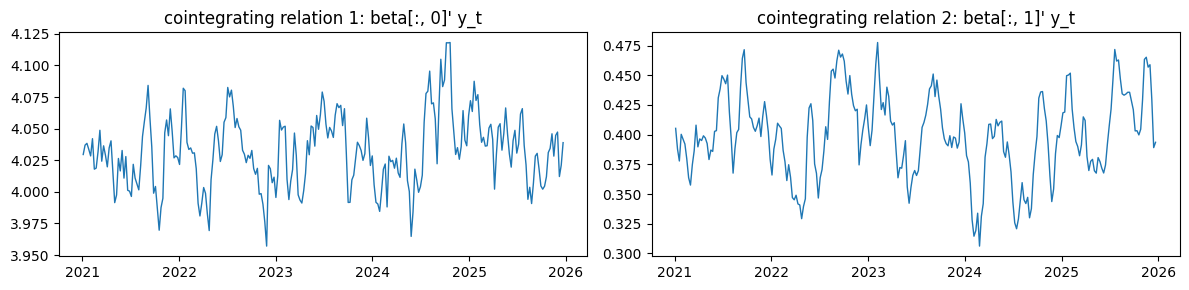

std of each relation: [0.0282 0.0352]
std of each series:   [0.2348 0.2043 0.185 ]


In [5]:
ec = data.endog.to_numpy() @ truth.beta

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for j, ax in enumerate(axes):
    ax.plot(data.endog.index, ec[:, j], lw=1)
    ax.set_title(f"cointegrating relation {j + 1}: beta[:, {j}]' y_t")
plt.tight_layout()
plt.show()

print("std of each relation:", ec.std(axis=0).round(4))
print("std of each series:  ", data.endog.std().to_numpy().round(4))

The relations move within a narrow band while the series drift. That is cointegration, and it is what `select_coint_rank` (notebook 10) and the model have to find.

`truth.const` is the constant that `deterministic="co"` estimates. It depends on `start_levels`, because it also pins the two relations at their starting values. `truth.growth` is the expected log growth per week of each series.

In [6]:
print("const: ", truth.const)
print("growth:", truth.growth)
print("weeks for sales to double at that growth:", round(float(np.log(2) / truth.growth[0])))

const:  [ 0.9695  0.0022 -0.071 ]
growth: [0.0027 0.0024 0.0021]
weeks for sales to double at that growth: 260


## 3. `exog_lag_share`: effects that arrive late

Real spend can take a week or more to show up in awareness. `exog_lag_share` moves a share of each driver effect one week later:

- same-week coefficients become `(1 - share) * b`
- lagged coefficients become `share * b`, stored in `truth.b_lag`

The total `b + b_lag` is unchanged, so the long-run effect of each driver is the same at any share. Fitting this data well needs `BayesianVECM(..., exog_lags=1)`. The Granger pretest in notebook 12 shows how to spot it before fitting.

In [7]:
lagged = simulate_brand_data(exog_lag_share=0.4)
row = 1  # brand_awareness
print("brand_awareness row of b:     ", lagged.truth.b[row])
print("brand_awareness row of b_lag: ", lagged.truth.b_lag[row])
print("sum, same as the default b:   ", lagged.truth.b[row] + lagged.truth.b_lag[row])
print("default b:                    ", truth.b[row])

brand_awareness row of b:      [0.0108 0.0072 0.0036 0.     0.    ]
brand_awareness row of b_lag:  [0.0072 0.0048 0.0024 0.     0.    ]
sum, same as the default b:    [0.018 0.012 0.006 0.    0.   ]
default b:                     [0.018 0.012 0.006 0.    0.   ]


The drivers themselves come from the same random draws whatever the share. Only the timing of their effect changes.

## 4. `exog_unit_root`: a trending driver

Interest rates do not return to a fixed level within five years. `exog_unit_root=("interest_rate",)` makes that driver a random walk. Its effect then runs through the change $\Delta x_t$, not the level, and `truth.differenced` records which drivers are affected.

The reason is a matter of orders of integration. Growth $\Delta y_t$ is stationary. A trending level cannot explain a stationary series without leaving a trend in the residuals. A levels fit gives a coefficient with no meaning, so the right regressor is `exog["interest_rate"].diff()`.

differenced: ('interest_rate',)


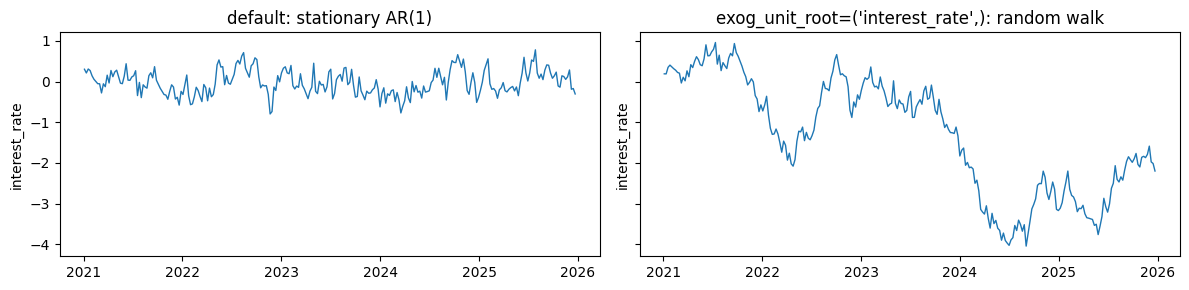

std of weekly change, default:   0.2396
std of weekly change, trending:  0.2198


In [8]:
trending = simulate_brand_data(exog_unit_root=("interest_rate",))
print("differenced:", trending.truth.differenced)

fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
axes[0].plot(data.exog.index, data.exog["interest_rate"], lw=1)
axes[0].set_title("default: stationary AR(1)")
axes[1].plot(trending.exog.index, trending.exog["interest_rate"], lw=1)
axes[1].set_title("exog_unit_root=('interest_rate',): random walk")
for ax in axes:
    ax.set_ylabel("interest_rate")
plt.tight_layout()
plt.show()

steps_default = np.diff(data.exog["interest_rate"].to_numpy())
steps_trending = np.diff(trending.exog["interest_rate"].to_numpy())
print("std of weekly change, default:  ", steps_default.std().round(4))
print("std of weekly change, trending: ", steps_trending.std().round(4))

The weekly changes are of similar size in both versions. Only the level behaves differently.

`check_stationarity` in notebook 12 labels this driver I(1) and says to pass it after `.diff()`. The practitioner guide's §3a fits both ways and shows what goes wrong in levels.

Invalid inputs fail early with a message naming the problem:

In [9]:
bad_calls = {
    "n_obs=2": {"n_obs": 2},
    "negative start level": {"start_levels": (1000.0, -1.0, 10.0)},
    "exog_lag_share=1.5": {"exog_lag_share": 1.5},
    "unknown driver": {"exog_unit_root": ("tv_spend",)},
}
for label, kwargs in bad_calls.items():
    try:
        simulate_brand_data(**kwargs)
    except ValueError as exc:
        print(f"{label:22s} -> {exc}")

n_obs=2                -> n_obs must be at least 3; got n_obs=2
negative start level   -> start_levels must be three positive numbers
exog_lag_share=1.5     -> exog_lag_share must be between 0 and 1; got 1.5
unknown driver         -> unknown exog_unit_root name(s) ['tv_spend']; choose from ['brand_spend', 'pr_reach', 'sponsorship_reach', 'interest_rate', 'consumer_confidence']


## 5. What this unlocks

Every check in the repo now runs on the same system with the same answers:

- `tests/` fit it and compare the posterior to `truth`.
- `tools/` scripts repeat that over many seeds to measure coverage. The results are in `docs/choosing_rank_and_lags.md`, `docs/granger_pretest.md` and the statsmodels comparison notebook.
- The practitioner guide fits it end to end and values each channel.

Notebook 12 runs the two checks that come before any fit: which series trend and which help predict which.